In [ ]:
%tensorflow_version 2.x
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

Colab only includes TensorFlow 2.x; %tensorflow_version has no effect.


In [ ]:
#for all homework, please set the seeds of your random number generators to your UCI ID number
np.random.seed(37509116)
tf.random.set_seed(37509116)

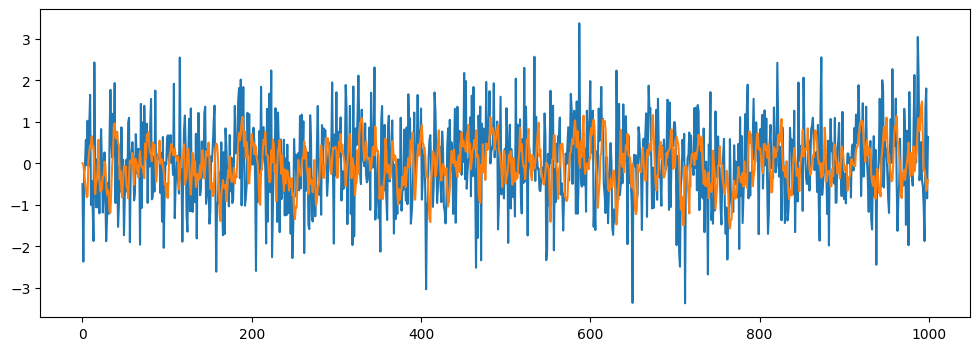

In [ ]:
#create a signal from filtered white noise
#here is the random number generator
from numpy.random import default_rng
rng = default_rng()
time_points = 1000
random_signal = rng.standard_normal(time_points)  #standard gaussian mean =0 std = 1
FIR_filter = [1,2,3,4,5]
FIR_filter = FIR_filter / np.sum(FIR_filter)
filtered_signal = np.convolve(random_signal, FIR_filter, 'full') #if use convolution mode:'same' will not line up
filtered_signal = np.append(0, filtered_signal[:len(random_signal)-1])  #will predict the NEXT output
plt.figure(figsize=(12,4), linewidth = 1)
plt.plot(random_signal)
plt.plot(filtered_signal)


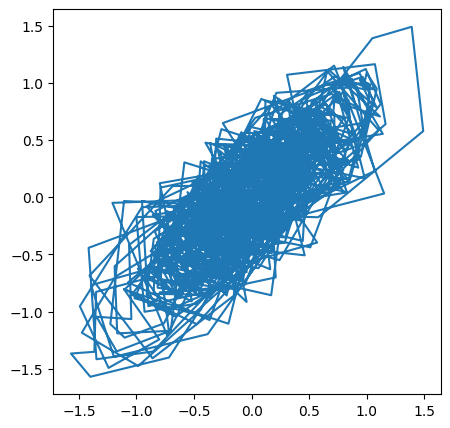

In [ ]:
# plot x(t) vs. x(t-1) to see a 2D "embedding" of a linear (and thus non-chaotic) system
# note that there is nothing that looks like limit-cycle behavior here
plt.figure(figsize=(5,5))
plt.plot(filtered_signal[:len(filtered_signal)-1],filtered_signal[1:]);

In [ ]:
#Make a series and dataframe with integer "timestamps"
randSeries = pd.Series(name='random', data=random_signal, index=range(0,len(random_signal)))
randDataFrame = randSeries.to_frame(name="random")
fsSeries = pd.Series(name='filtered', data=filtered_signal, index=range(0,len(filtered_signal)))
fsDataFrame = fsSeries.to_frame(name="filtered")
fsDataFrame

,filtered
0,0.000000
1,-0.033408
2,-0.224772
3,-0.434687
4,-0.644291
...,...
995,-0.153184
996,-0.321403
997,-0.662969
998,-0.545884


In [ ]:
#will use the last test_size elements in the series for test set validation and early stopping
#  in this case we need both the original random series and the filtered series
#  so we can predict one from the other
test_size = 100
test_ind = len(fsDataFrame)-test_size  #index of the first element to predict -1
fsTrain=fsDataFrame.iloc[:test_ind]  #train on everything before that
fsTest=fsDataFrame.iloc[test_ind:]   #test on everything after that
randTrain=randDataFrame.iloc[:test_ind]
randTest=randDataFrame.iloc[test_ind:]
#we will not do scaling this time, because we like the original scale (standard normal)

In [ ]:
#generator for the timeseries data
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
predict_length = len(FIR_filter)  #this is cheating; we know the length of the filter
#we are trying to "learn" the filter.  input is random sequence output is filtered sequence
#WARNING: you cannot pass a dataframe to timeseriesgenerator.  must be a numpy array
generator = TimeseriesGenerator(randTrain.to_numpy(), fsTrain.to_numpy(), length = predict_length, batch_size=1)
generator[0]




(array([[[-0.50112743],
         [-2.36933004],
         [-0.27826293],
         [ 0.00466168],
         [ 0.56646943]]]),
 array([[-0.81613022]]))

In [ ]:
#generator for the validation data
validation_generator = TimeseriesGenerator(randTest.to_numpy(),fsTest.to_numpy(), length=predict_length, batch_size=1)

In [ ]:
#create the network
#from tensorflow.tools.docs.doc_controls import do_not_doc_inheritable
#from matplotlib import use
from tensorflow.python.keras.engine.base_layer_utils import uses_keras_history
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Reshape, Flatten
from tensorflow.keras.layers import LSTM
n_features = 1
model = Sequential()
#if you don't flatten, will get a separate single-input net for each time value
#don't need to do this for LSTM layers; they flatten implicitly
model.add(Flatten(input_shape = (predict_length, n_features)))
model.add(Dense(1))  #this is a single output linear network
model.compile(optimizer='adam', loss='mse')
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 5)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6 (24.00 B)

 Trainable params: 6 (24.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(monitor='val_loss',patience=2)

In [ ]:
model.fit(generator,epochs=10,
                    validation_data=validation_generator,
                   callbacks=[early_stop])

Epoch 1/10


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


895/895 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 1.5754 - val_loss: 0.7521
Epoch 2/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.4651 - val_loss: 0.1612
Epoch 3/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0975 - val_loss: 0.0170
Epoch 4/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0078 - val_loss: 5.5726e-04
Epoch 5/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 2.2973e-04 - val_loss: 2.9297e-06
Epoch 6/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 9.6029e-07 - val_loss: 8.6597e-10
Epoch 7/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 1.9423e-10 - val_loss: 2.8114e-13
Epoch 8/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 1.8665e-13 - val_loss: 1.2717e-13
Epoch 9/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 8.2820e-14 - val_loss: 7.6547e-14
Epoch 10/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 5.1061e-14 - val_loss: 3.6673e-14


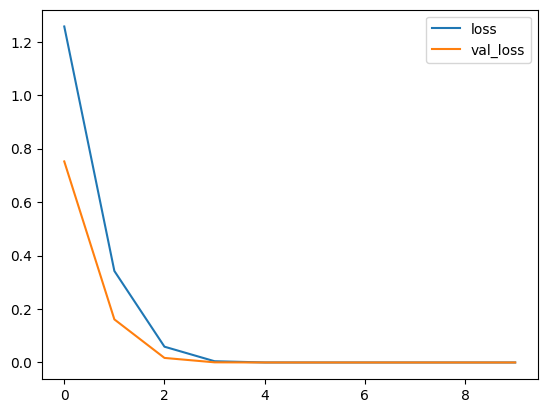

In [ ]:
losses = pd.DataFrame(model.history.history)
losses.plot();

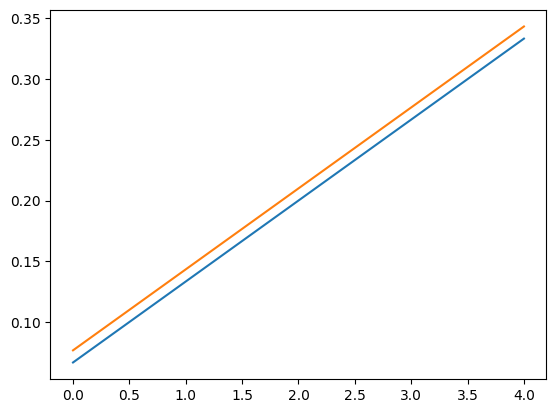

In [ ]:
plt.figure
model_weights = model.get_weights()[0]  #[0] converts this to a flat numpy array
plt.plot(model_weights[::-1])  #weights are in opposite order because of the way generator works
plt.plot(FIR_filter +0.01);  #add 0.01 so you can see both

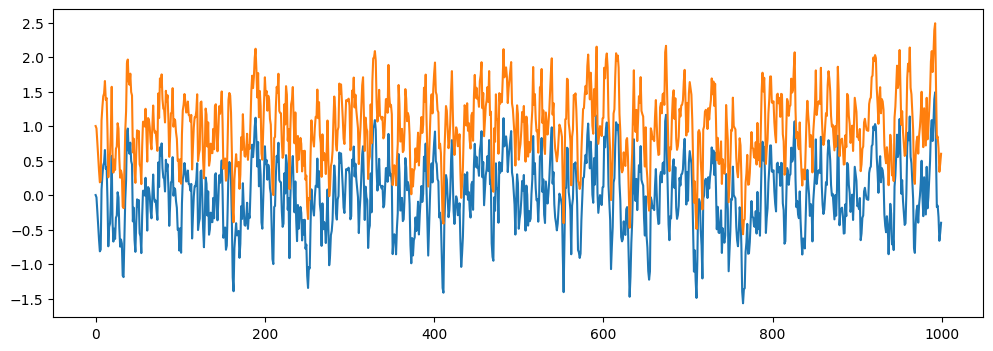

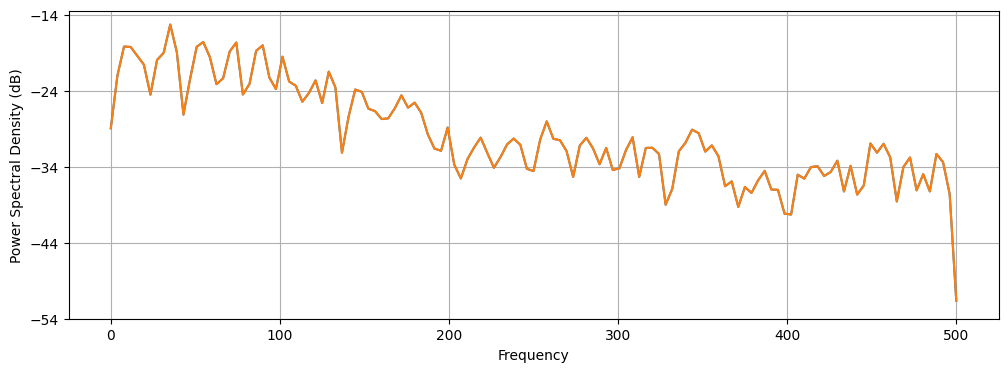

In [ ]:
#compare the predicted timeseries
predicted_FIR_filter= np.fliplr([model_weights.copy()])[0]  #model weights are reverse order and column vector
predicted_FIR_filter=predicted_FIR_filter.transpose()[0]  #make a row vector out of this. [0] converts matrix back to vector
predicted_filtered_signal = np.convolve(random_signal, predicted_FIR_filter, 'full') #now you can convolve
predicted_filtered_signal = np.append(0, predicted_filtered_signal[:len(random_signal)-1]) #adjust for prediction as before

plt.figure(figsize=(12,4), linewidth = 1)
plt.plot(predicted_filtered_signal)
plt.plot(filtered_signal+1);  # to visualize because signals will be identical

plt.figure(figsize=(12,4))
plt.psd(predicted_filtered_signal, Fs=1000, scale_by_freq=0);
plt.psd(filtered_signal, Fs=1000, scale_by_freq=0);

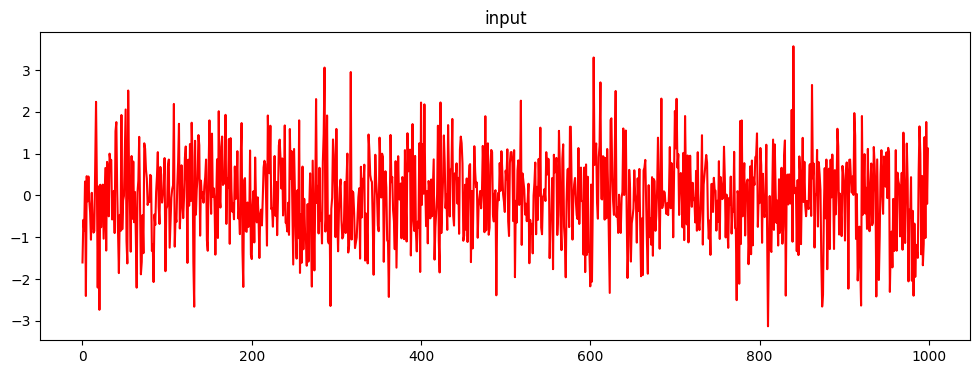

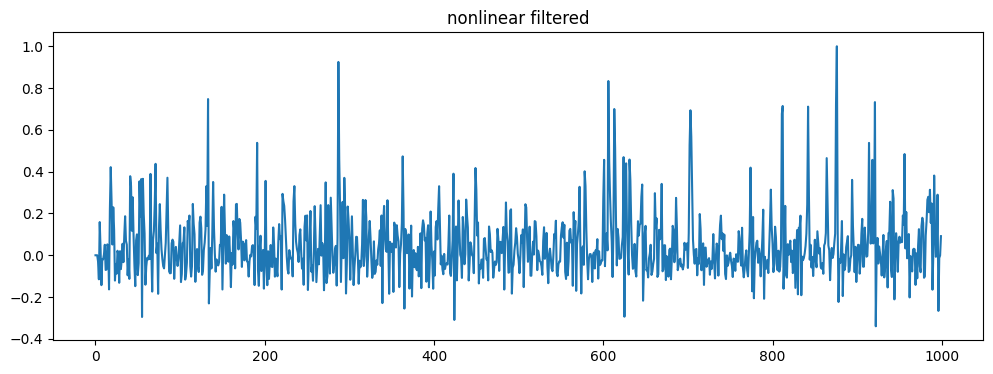

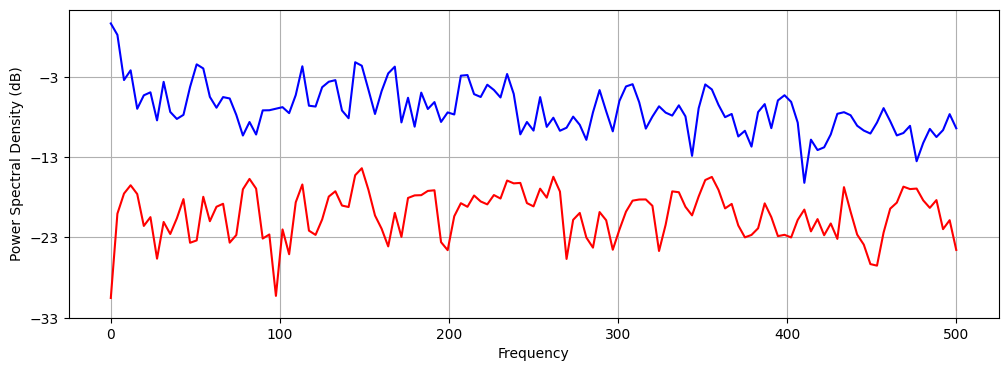

In [ ]:
#create a nonlinear signal from filtered white noise using a Volterra expansion

#here is the random number generator, same as before, to create the input
from numpy.random import default_rng
rng = default_rng()
time_points = 1000
random_signal = rng.standard_normal(time_points)  #standard gaussian mean =0 std = 1

#now create the volterra kernel
volterra_memory = 3  #number of past timepoints that contribute to the expansion
volterra_order = 2   #maximum polynomial order; more than 2 is usually unwieldy
                    #note that volterra_order=1 just gives a linear filter
#calculate the length of the kernel.  1(constant term) + memory(linear term) + memory^2 in this case
filter_length = 1
for n in range(1, volterra_order+1):
  filter_length = filter_length + volterra_memory**n
y = np.zeros(volterra_memory)  #set the first ones to zero so outputs line up
#now make some random coefficients (normally these might come from a polynomial fitting routine)
volterra_coefficients = rng.standard_normal(filter_length)

#now run the volterra kernel over the input to generate the output
for t in range(0,time_points-volterra_memory):
    x = random_signal[t:t+volterra_memory]  #last 3 time points
    xn = [1]  #constant term in volterra expansion
    inp = [1]
    for n in range(1,volterra_order+1):  #loop over the power (order) of volterra terms
      xn = np.outer(xn,x).ravel()    #this creates all the products x(t-i)x(t-j)...x(t-w) for the n'th order term
      inp = np.append(inp,xn)        #include all the terms, constant+linear+secondorder+...
                                     #each term has length volterra_memory**n including all possible cross-products
    y = np.append(y,np.dot(inp,volterra_coefficients))  #dot product multiplies by volterra coefficients to get output

#scale the range; tensorflow models learn more slowly if the output range is large
nonlinear_filtered_signal = y / np.max(np.abs(y))

plt.figure(figsize=(12,4))
plt.plot(random_signal,'r')
plt.title('input')
plt.figure(figsize=(12,4))
plt.plot(nonlinear_filtered_signal);
plt.title('nonlinear filtered');

plt.figure(figsize=(12,4))
plt.psd(random_signal, color='r', Fs=1000, scale_by_freq=0);
plt.psd(y, Fs=1000, color = 'b', scale_by_freq=0);



In [ ]:
#Make a series and dataframe with integer "timestamps"
randSeries = pd.Series(name='random', data=random_signal, index=range(0,len(random_signal)))
randDataFrame = randSeries.to_frame(name="random")
fsSeries = pd.Series(name='filtered', data=nonlinear_filtered_signal, index=range(0,len(filtered_signal)))
fsDataFrame = fsSeries.to_frame(name="filtered")

#will use the last test_size elements in the series for test set validation and early stopping
#  in this case we need both the original random series and the filtered series
#  so we can predict one from the other
test_size = 100
test_ind = len(fsDataFrame)-test_size  #index of the first element to predict -1
fsTrain=fsDataFrame.iloc[:test_ind]  #train on everything before that
fsTest=fsDataFrame.iloc[test_ind:]   #test on everything after that
randTrain=randDataFrame.iloc[:test_ind]
randTest=randDataFrame.iloc[test_ind:]
#we will not do scaling this time, because we like the original scale (standard normal)

In [ ]:
#generator for the timeseries data
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
predict_length = volterra_memory  #this is cheating; we know the length of the filter
#we are trying to "learn" the filter.  input is random sequence output is filtered sequence
#WARNING: you cannot pass a dataframe to timeseriesgenerator.  must be a numpy array
generator = TimeseriesGenerator(randTrain.to_numpy(), fsTrain.to_numpy(), length = predict_length, batch_size=1)

#generator for the validation data
validation_generator = TimeseriesGenerator(randTest.to_numpy(),fsTest.to_numpy(), length=predict_length, batch_size=1)

In [ ]:
#create the network
n_features = 1

#will use two nonlinear layers so that we can capture second-order interactions between inputs in the first layer
model = Sequential()
model.add(Flatten(input_shape = (predict_length, n_features)))
model.add(Dense(20, activation='sigmoid'))  #we know this will be a smooth (polynomial) function, so use smooth activation
model.add(Dense(20, activation = 'sigmoid'))
model.add(Dense(1))  #this is a single output linear network at the top to allow scaling to the correct output range
model.compile(optimizer='adam', loss='mse')  #mse because is a regression problem
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 3)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 521 (2.04 KB)

 Trainable params: 521 (2.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#longer early stopping because the first few iterations often dont seem to decrease the error
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(monitor='val_loss',patience=5)

Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


897/897 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0441 - val_loss: 0.0240
Epoch 2/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0220 - val_loss: 0.0244
Epoch 3/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0188 - val_loss: 0.0249
Epoch 4/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0195 - val_loss: 0.0261
Epoch 5/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0188 - val_loss: 0.0244
Epoch 6/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0173 - val_loss: 0.0217
Epoch 7/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0135 - val_loss: 0.0242
Epoch 8/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0167 - val_loss: 0.0263
Epoch 9/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0170 - val_loss: 0.0218
Epoch 10/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0133 - val_loss: 0.0174
Epoch 11/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0117 - val_loss: 0.0096
Epoch 12/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.

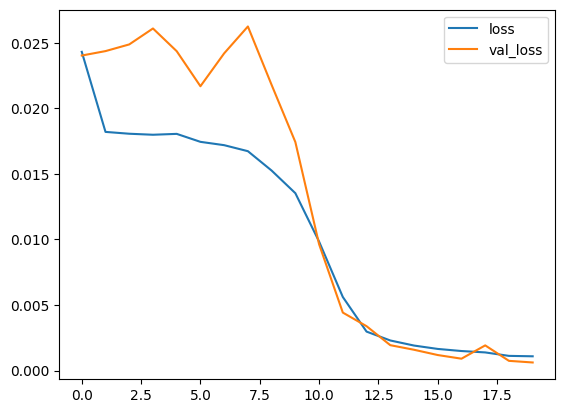

In [ ]:
#it can often take a while before the error starts to decrease.  if it gets stuck, try again
model.fit(generator,epochs=20,
                    validation_data=validation_generator,
                   callbacks=[early_stop])
losses = pd.DataFrame(model.history.history)
losses.plot();

897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


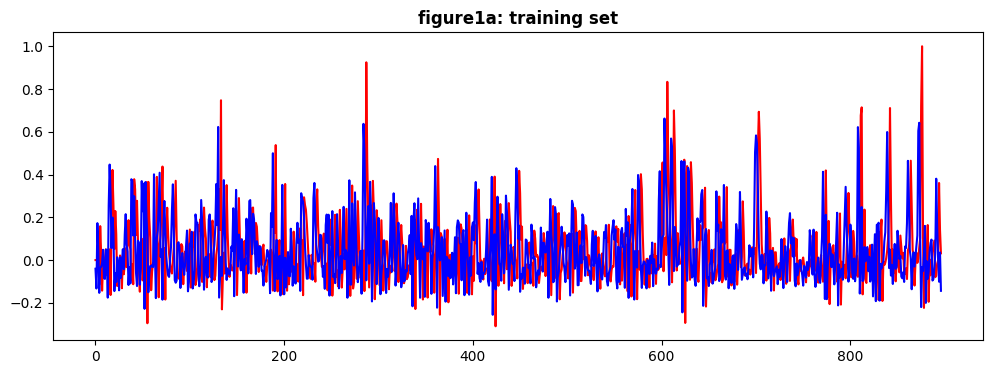

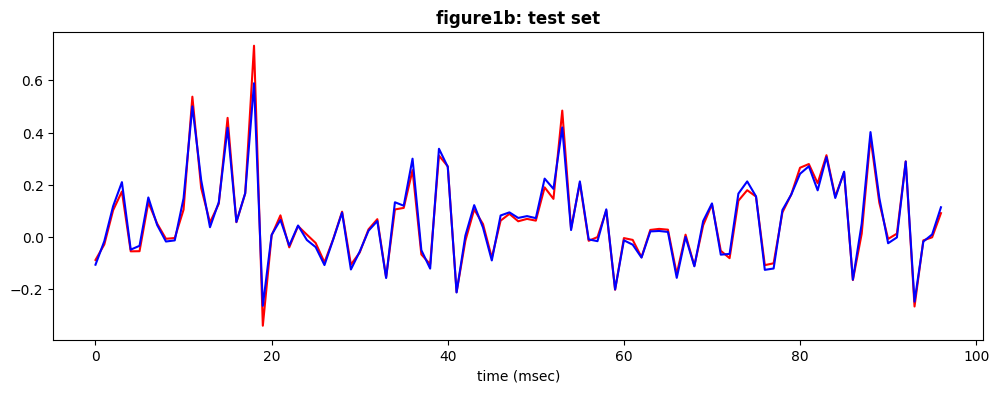

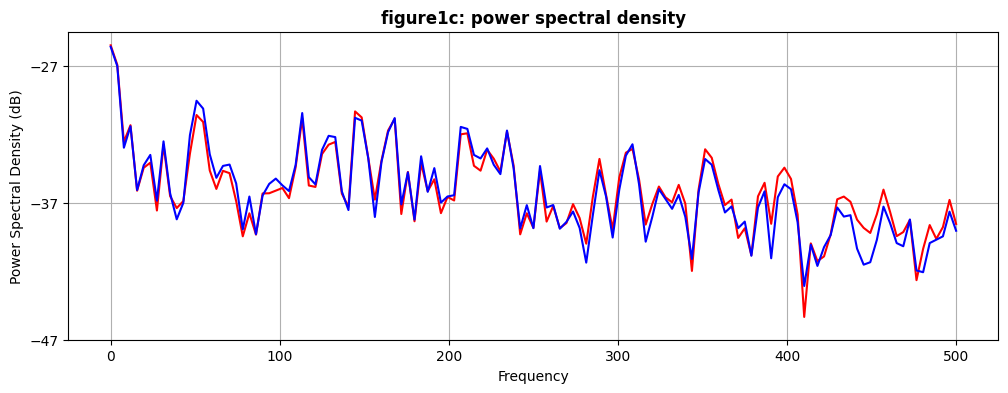

In [ ]:
#compare the predicted timeseries
predicted_outputs = model.predict(generator)
predicted_validation = model.predict(validation_generator)

plt.figure(figsize=(12,4), linewidth = 1)
plt.plot(nonlinear_filtered_signal[:len(predicted_outputs)],'r')
plt.plot(predicted_outputs,'b')
plt.title('figure1a: training set',fontweight="bold")
plt.figure(figsize=(12,4), linewidth = 1)
plt.plot(nonlinear_filtered_signal[-len(predicted_validation):],'r')
plt.plot(predicted_validation,'b')
plt.title('figure1b: test set',fontweight="bold");
plt.xlabel('time (msec)')

plt.figure(figsize=(12,4))
plt.psd(nonlinear_filtered_signal, color='r', Fs=1000, scale_by_freq=0);
plt.psd(predicted_outputs.ravel(), Fs=1000, color = 'b', scale_by_freq=0);  #use ravel to make a horizontal array
plt.title('figure1c: power spectral density',fontweight="bold");



/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 3)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 40)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 20)             │           820 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,001 (3.91 KB)

 Trainable params: 1,001 (3.91 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


897/897 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0458 - val_loss: 0.0430
Epoch 2/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0344 - val_loss: 0.0399
Epoch 3/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0308 - val_loss: 0.0415
Epoch 4/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0317 - val_loss: 0.0364
Epoch 5/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0312 - val_loss: 0.0351
Epoch 6/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0333 - val_loss: 0.0396
Epoch 7/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0344 - val_loss: 0.0400
Epoch 8/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0307 - val_loss: 0.0315
Epoch 9/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0252 - val_loss: 0.0278
Epoch 10/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0187 - val_loss: 0.0166
Epoch 11/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0166 - val_loss: 0.0141
Epoch 12/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.

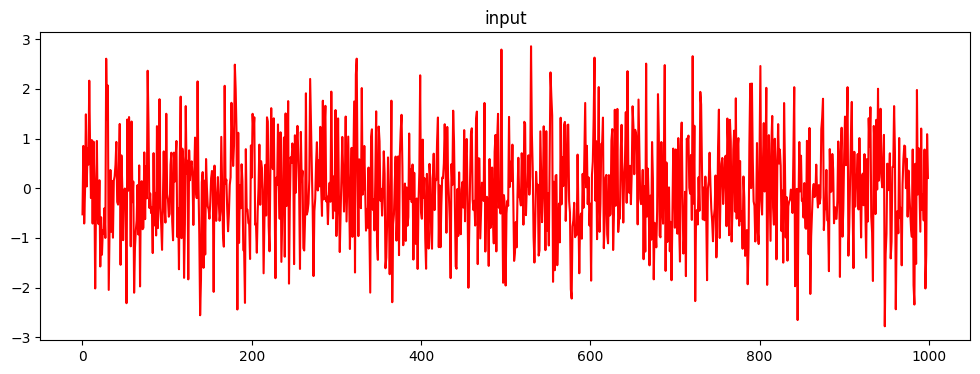

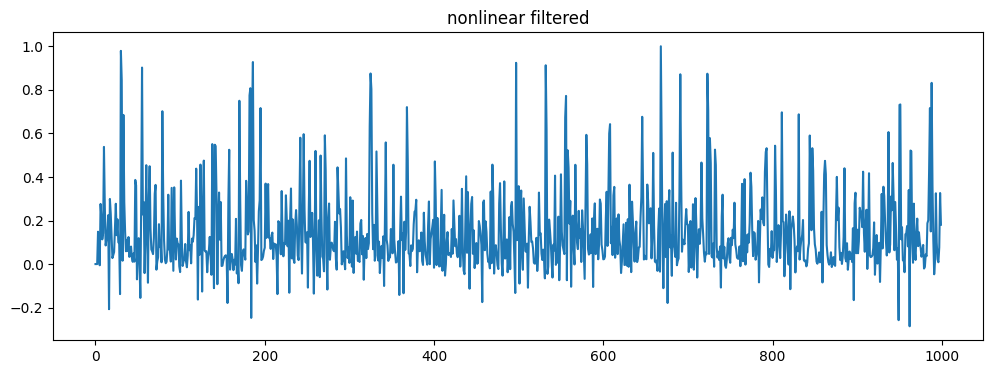

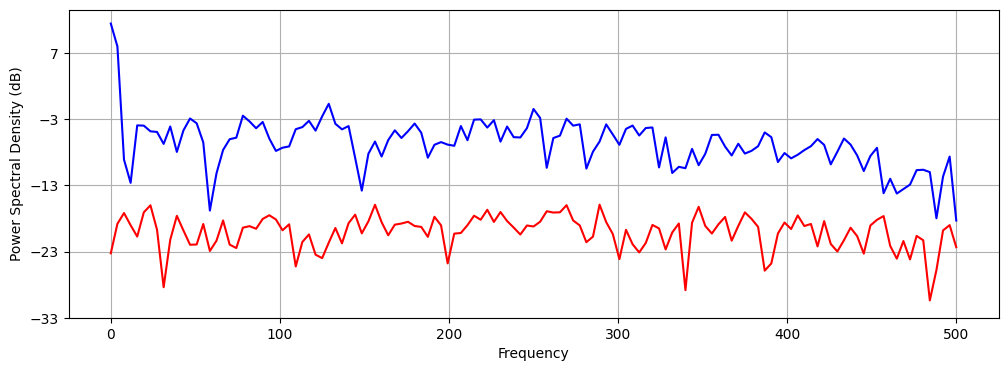

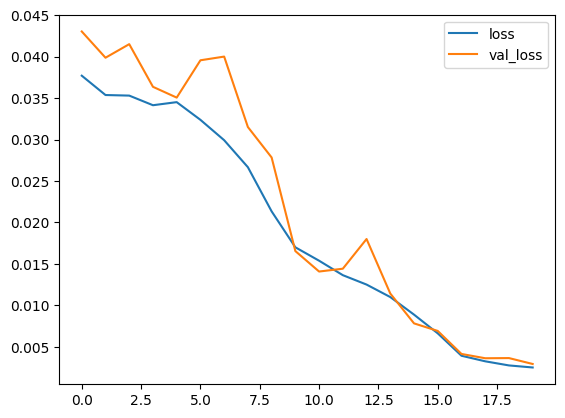

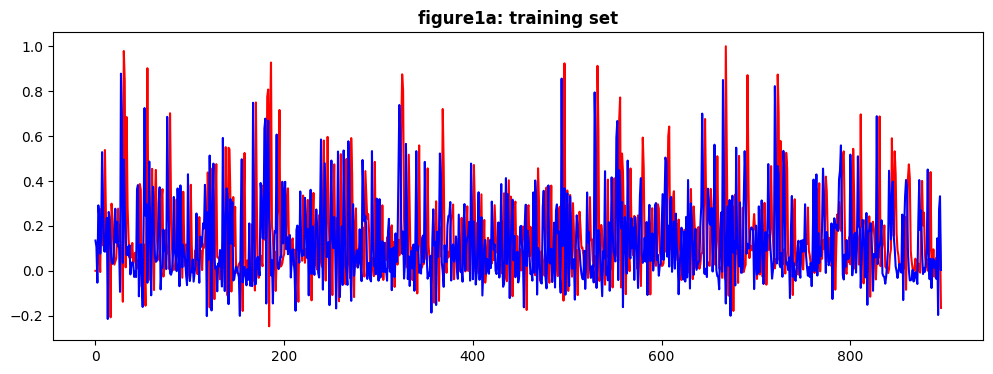

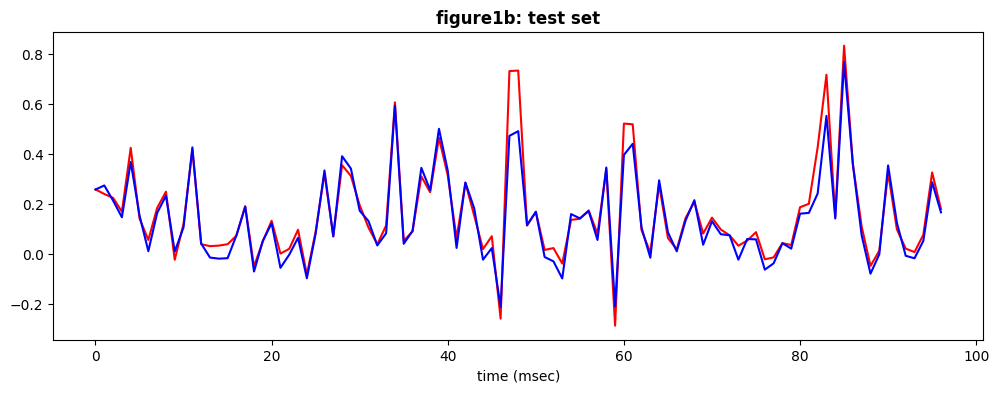

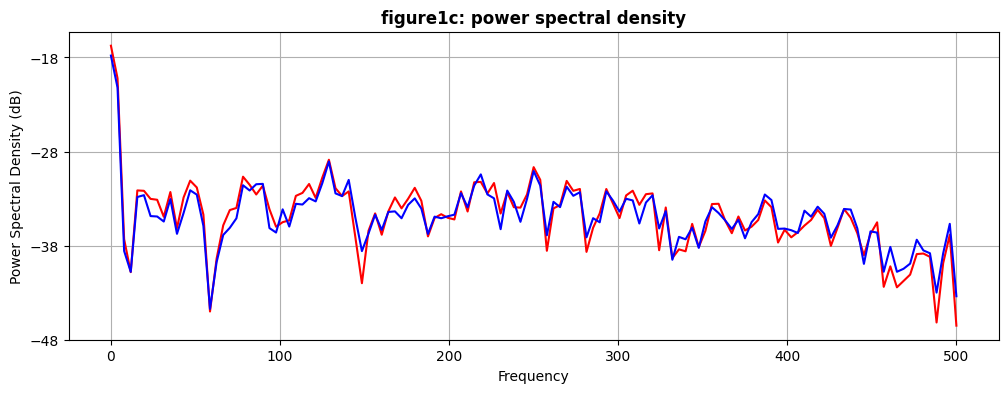

In [ ]:
## HOMEWORK volterra_order 2 implemented using additional hidden layer
#create a nonlinear signal from filtered white noise using a Volterra expansion

#here is the random number generator, same as before, to create the input
from numpy.random import default_rng
rng = default_rng()
time_points = 1000
random_signal = rng.standard_normal(time_points)  #standard gaussian mean =0 std = 1

#now create the volterra kernel
volterra_memory = 3  #number of past timepoints that contribute to the expansion // predict length
volterra_order = 2   #maximum polynomial order; more than 2 is usually unwieldy
                    #note that volterra_order=1 just gives a linear filter
#calculate the length of the kernel.  1(constant term) + memory(linear term) + memory^2 in this case
filter_length = 1
for n in range(1, volterra_order+1):
  filter_length = filter_length + volterra_memory**n
y = np.zeros(volterra_memory)  #set the first ones to zero so outputs line up
#now make some random coefficients (normally these might come from a polynomial fitting routine)
volterra_coefficients = rng.standard_normal(filter_length)

#now run the volterra kernel over the input to generate the output
for t in range(0,time_points-volterra_memory):
    x = random_signal[t:t+volterra_memory]  #last 3 time points
    xn = [1]  #constant term in volterra expansion
    inp = [1]
    for n in range(1,volterra_order+1):  #loop over the power (order) of volterra terms
      xn = np.outer(xn,x).ravel()    #this creates all the products x(t-i)x(t-j)...x(t-w) for the n'th order term
      inp = np.append(inp,xn)        #include all the terms, constant+linear+secondorder+...
                                     #each term has length volterra_memory**n including all possible cross-products
    y = np.append(y,np.dot(inp,volterra_coefficients))  #dot product multiplies by volterra coefficients to get output

#scale the range; tensorflow models learn more slowly if the output range is large
nonlinear_filtered_signal = y / np.max(np.abs(y))

plt.figure(figsize=(12,4))
plt.plot(random_signal,'r')
plt.title('input')
plt.figure(figsize=(12,4))
plt.plot(nonlinear_filtered_signal);
plt.title('nonlinear filtered');

plt.figure(figsize=(12,4))
plt.psd(random_signal, color='r', Fs=1000, scale_by_freq=0);
plt.psd(y, Fs=1000, color = 'b', scale_by_freq=0);


#Make a series and dataframe with integer "timestamps"
randSeries = pd.Series(name='random', data=random_signal, index=range(0,len(random_signal)))
randDataFrame = randSeries.to_frame(name="random")
fsSeries = pd.Series(name='filtered', data=nonlinear_filtered_signal, index=range(0,len(filtered_signal)))
fsDataFrame = fsSeries.to_frame(name="filtered")

#will use the last test_size elements in the series for test set validation and early stopping
#  in this case we need both the original random series and the filtered series
#  so we can predict one from the other
test_size = 100
test_ind = len(fsDataFrame)-test_size  #index of the first element to predict -1
fsTrain=fsDataFrame.iloc[:test_ind]  #train on everything before that
fsTest=fsDataFrame.iloc[test_ind:]   #test on everything after that
randTrain=randDataFrame.iloc[:test_ind]
randTest=randDataFrame.iloc[test_ind:]
#we will not do scaling this time, because we like the original scale (standard normal)
#generator for the timeseries data
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
predict_length = volterra_memory  #this is cheating; we know the length of the filter
#we are trying to "learn" the filter.  input is random sequence output is filtered sequence
#WARNING: you cannot pass a dataframe to timeseriesgenerator.  must be a numpy array
generator = TimeseriesGenerator(randTrain.to_numpy(), fsTrain.to_numpy(), length = predict_length, batch_size=1)

#generator for the validation data
validation_generator = TimeseriesGenerator(randTest.to_numpy(),fsTest.to_numpy(), length=predict_length, batch_size=1)
#create the network
n_features = 1

#will use two nonlinear layers so that we can capture second-order interactions between inputs in the first layer
model = Sequential()
model.add(Flatten(input_shape = (predict_length, n_features)))
model.add(Dense(40, activation='sigmoid'))
model.add(Dense(20, activation = 'sigmoid'))
model.add(Dense(1))  #this is a single output linear network at the top to allow scaling to the correct output range
model.compile(optimizer='adam', loss='mse')  #mse because is a regression problem
model.summary()
#longer early stopping because the first few iterations often dont seem to decrease the error
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(monitor='val_loss',patience=5)



#it can often take a while before the error starts to decrease.  if it gets stuck, try again
model.fit(generator,epochs=20,
                    validation_data=validation_generator,
                   callbacks=[early_stop])
losses = pd.DataFrame(model.history.history)
losses.plot();



#compare the predicted timeseries
predicted_outputs = model.predict(generator)
predicted_validation = model.predict(validation_generator)

plt.figure(figsize=(12,4), linewidth = 1)
plt.plot(nonlinear_filtered_signal[:len(predicted_outputs)],'r')
plt.plot(predicted_outputs,'b')
plt.title('figure1a: training set',fontweight="bold")
plt.figure(figsize=(12,4), linewidth = 1)
plt.plot(nonlinear_filtered_signal[-len(predicted_validation):],'r')
plt.plot(predicted_validation,'b')
plt.title('figure1b: test set',fontweight="bold");
plt.xlabel('time (msec)')

plt.figure(figsize=(12,4))
plt.psd(nonlinear_filtered_signal, color='r', Fs=1000, scale_by_freq=0);
plt.psd(predicted_outputs.ravel(), Fs=1000, color = 'b', scale_by_freq=0);  #use ravel to make a horizontal array
plt.title('figure1c: power spectral density',fontweight="bold");


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 3)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 80)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 20)             │         1,620 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,961 (7.66 KB)

 Trainable params: 1,961 (7.66 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


897/897 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0191 - val_loss: 0.0086
Epoch 2/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0144 - val_loss: 0.0089
Epoch 3/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0190 - val_loss: 0.0060
Epoch 4/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0193 - val_loss: 0.0055
Epoch 5/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0158 - val_loss: 0.0080
Epoch 6/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0122 - val_loss: 0.0051
Epoch 7/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0132 - val_loss: 0.0051
Epoch 8/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0140 - val_loss: 0.0051
Epoch 9/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0147 - val_loss: 0.0039
Epoch 10/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0142 - val_loss: 0.0049
Epoch 11/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0095 - val_loss: 0.0031
Epoch 12/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.

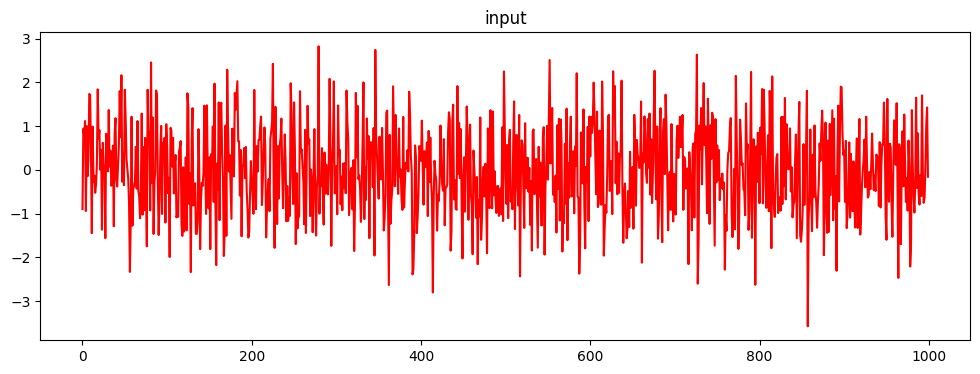

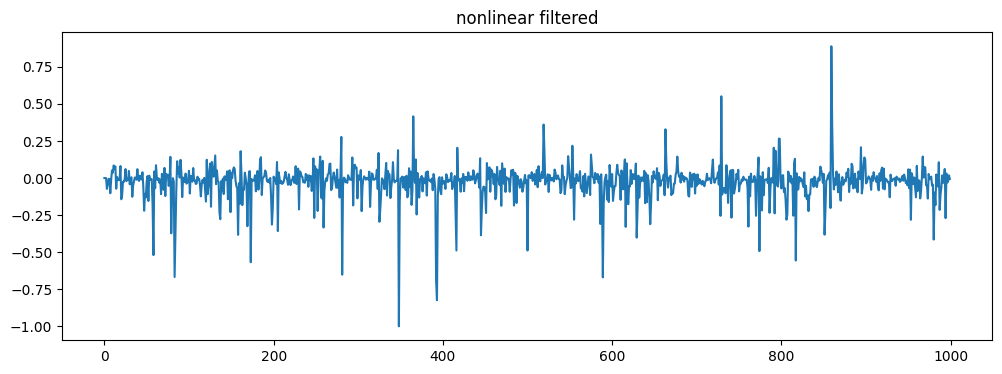

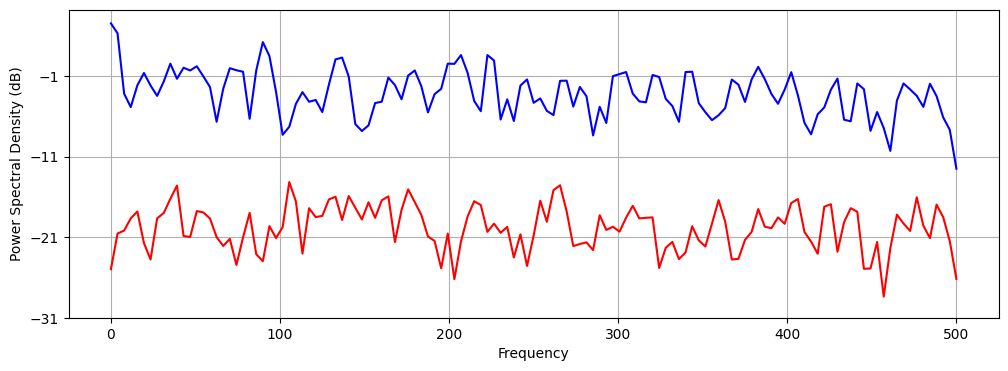

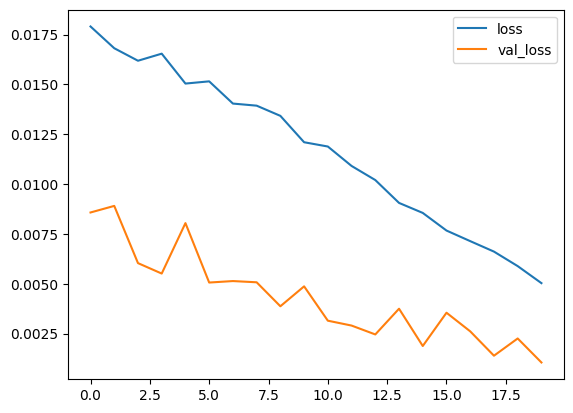

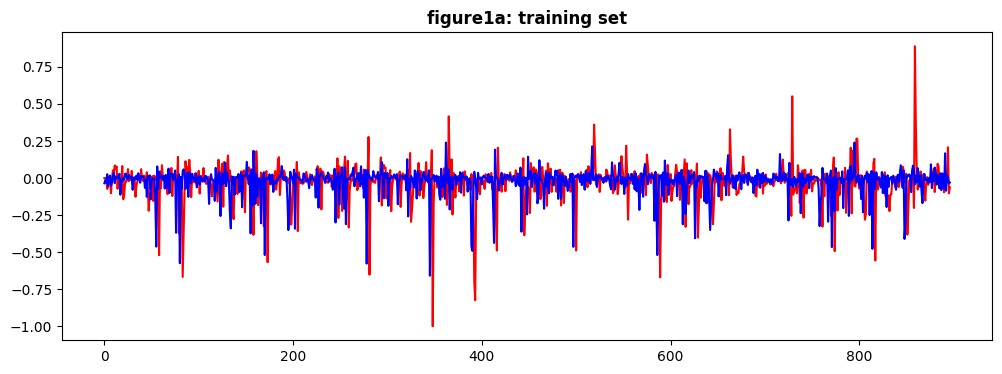

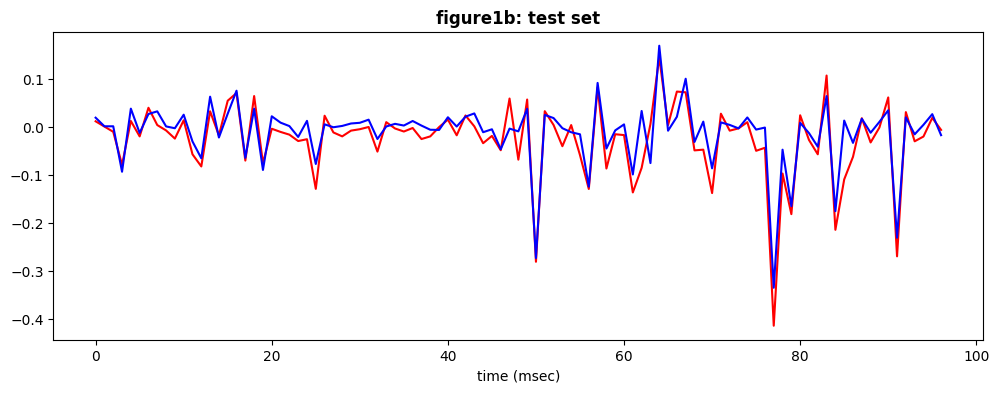

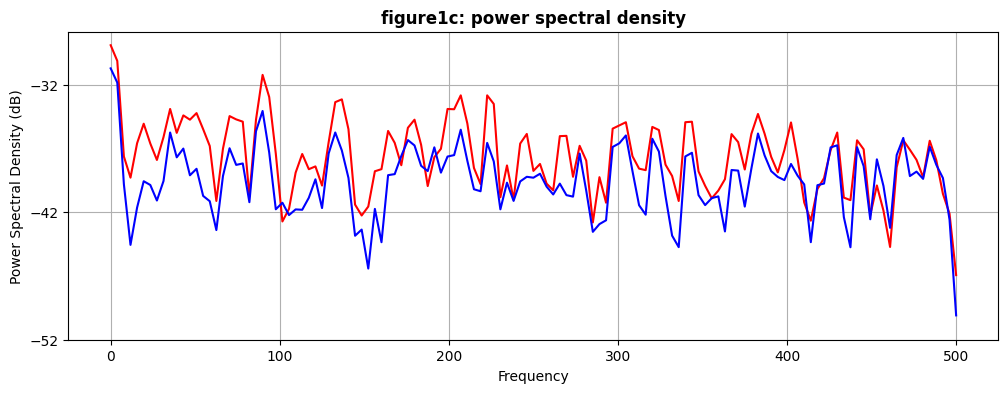

In [ ]:
## HOMEWORK volterra_order 3 implemented using additional hidden layer

#create a nonlinear signal from filtered white noise using a Volterra expansion

#here is the random number generator, same as before, to create the input
from numpy.random import default_rng
rng = default_rng()
time_points = 1000
random_signal = rng.standard_normal(time_points)  #standard gaussian mean =0 std = 1

#now create the volterra kernel
volterra_memory = 3  #number of past timepoints that contribute to the expansion // predict length
volterra_order = 3   #maximum polynomial order; more than 2 is usually unwieldy
                    #note that volterra_order=1 just gives a linear filter
#calculate the length of the kernel.  1(constant term) + memory(linear term) + memory^2 in this case
filter_length = 1
for n in range(1, volterra_order+1):
  filter_length = filter_length + volterra_memory**n
y = np.zeros(volterra_memory)  #set the first ones to zero so outputs line up
#now make some random coefficients (normally these might come from a polynomial fitting routine)
volterra_coefficients = rng.standard_normal(filter_length)

#now run the volterra kernel over the input to generate the output
for t in range(0,time_points-volterra_memory):
    x = random_signal[t:t+volterra_memory]  #last 3 time points
    xn = [1]  #constant term in volterra expansion
    inp = [1]
    for n in range(1,volterra_order+1):  #loop over the power (order) of volterra terms // volterra_order+1 because range in python is not inclusive of end terms
      xn = np.outer(xn,x).ravel()    #this creates all the products x(t-i)x(t-j)...x(t-w) for the n'th order term
      inp = np.append(inp,xn)        #include all the terms, constant+linear+secondorder+...
                                     #each term has length volterra_memory**n including all possible cross-products
    y = np.append(y,np.dot(inp,volterra_coefficients))  #dot product multiplies by volterra coefficients to get output

#scale the range; tensorflow models learn more slowly if the output range is large
nonlinear_filtered_signal = y / np.max(np.abs(y))

plt.figure(figsize=(12,4))
plt.plot(random_signal,'r')
plt.title('input')
plt.figure(figsize=(12,4))
plt.plot(nonlinear_filtered_signal);
plt.title('nonlinear filtered');

plt.figure(figsize=(12,4))
plt.psd(random_signal, color='r', Fs=1000, scale_by_freq=0);
plt.psd(y, Fs=1000, color = 'b', scale_by_freq=0);


#Make a series and dataframe with integer "timestamps"
randSeries = pd.Series(name='random', data=random_signal, index=range(0,len(random_signal)))
randDataFrame = randSeries.to_frame(name="random")
fsSeries = pd.Series(name='filtered', data=nonlinear_filtered_signal, index=range(0,len(filtered_signal)))
fsDataFrame = fsSeries.to_frame(name="filtered")

#will use the last test_size elements in the series for test set validation and early stopping
#  in this case we need both the original random series and the filtered series
#  so we can predict one from the other
test_size = 100
test_ind = len(fsDataFrame)-test_size  #index of the first element to predict -1
fsTrain=fsDataFrame.iloc[:test_ind]  #train on everything before that
fsTest=fsDataFrame.iloc[test_ind:]   #test on everything after that
randTrain=randDataFrame.iloc[:test_ind]
randTest=randDataFrame.iloc[test_ind:]
#we will not do scaling this time, because we like the original scale (standard normal)
#generator for the timeseries data
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
predict_length = volterra_memory  #this is cheating; we know the length of the filter
#we are trying to "learn" the filter.  input is random sequence output is filtered sequence
#WARNING: you cannot pass a dataframe to timeseriesgenerator.  must be a numpy array
generator = TimeseriesGenerator(randTrain.to_numpy(), fsTrain.to_numpy(), length = predict_length, batch_size=1)

#generator for the validation data
validation_generator = TimeseriesGenerator(randTest.to_numpy(),fsTest.to_numpy(), length=predict_length, batch_size=1)
#create the network
n_features = 1

#will use two nonlinear layers so that we can capture second-order interactions between inputs in the first layer
model = Sequential()
model.add(Flatten(input_shape = (predict_length, n_features)))
model.add(Dense(80, activation='sigmoid'))  #we know this will be a smooth (polynomial) function, so use smooth activation
model.add(Dense(20, activation = 'sigmoid'))
model.add(Dense(1))  #this is a single output linear network at the top to allow scaling to the correct output range
model.compile(optimizer='adam', loss='mse')  #mse because is a regression problem
model.summary()
#longer early stopping because the first few iterations often dont seem to decrease the error
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(monitor='val_loss',patience=5)



#it can often take a while before the error starts to decrease.  if it gets stuck, try again
model.fit(generator,epochs=20,
                    validation_data=validation_generator,
                   callbacks=[early_stop])
losses = pd.DataFrame(model.history.history)
losses.plot();



#compare the predicted timeseries
predicted_outputs = model.predict(generator)
predicted_validation = model.predict(validation_generator)

plt.figure(figsize=(12,4), linewidth = 1)
plt.plot(nonlinear_filtered_signal[:len(predicted_outputs)],'r')
plt.plot(predicted_outputs,'b')
plt.title('figure1a: training set',fontweight="bold")
plt.figure(figsize=(12,4), linewidth = 1)
plt.plot(nonlinear_filtered_signal[-len(predicted_validation):],'r')
plt.plot(predicted_validation,'b')
plt.title('figure1b: test set',fontweight="bold");
plt.xlabel('time (msec)')

plt.figure(figsize=(12,4))
plt.psd(nonlinear_filtered_signal, color='r', Fs=1000, scale_by_freq=0);
plt.psd(predicted_outputs.ravel(), Fs=1000, color = 'b', scale_by_freq=0);  #use ravel to make a horizontal array
plt.title('figure1c: power spectral density',fontweight="bold");


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 3)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 80)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 20)             │         1,620 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,961 (7.66 KB)

 Trainable params: 1,961 (7.66 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


897/897 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0072 - val_loss: 0.0031
Epoch 2/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0028 - val_loss: 0.0028
Epoch 3/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0012 - val_loss: 0.0081
Epoch 4/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0024 - val_loss: 0.0014
Epoch 5/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 9.3039e-04 - val_loss: 0.0015
Epoch 6/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 6.9102e-04 - val_loss: 0.0045
Epoch 7/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0013 - val_loss: 6.2899e-04
Epoch 8/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 5.7872e-04 - val_loss: 0.0015
Epoch 9/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 6.3892e-04 - val_loss: 0.0016
Epoch 10/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 8.0589e-04 - val_loss: 5.5547e-04
Epoch 11/20
897/897 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 4.1421e-04 - val_loss: 9.2001e-04
Epoch 12/20
897/897 ━━━━━━━

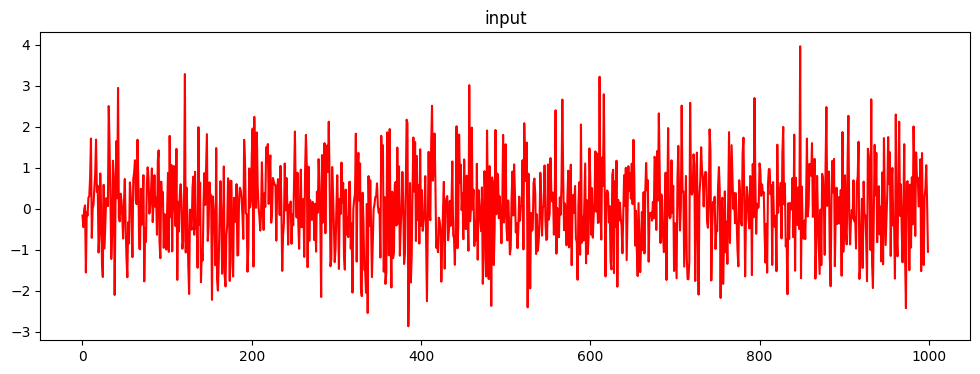

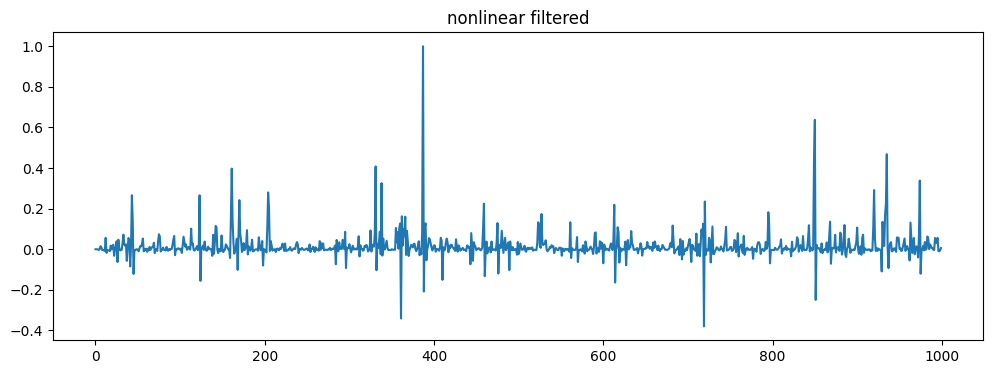

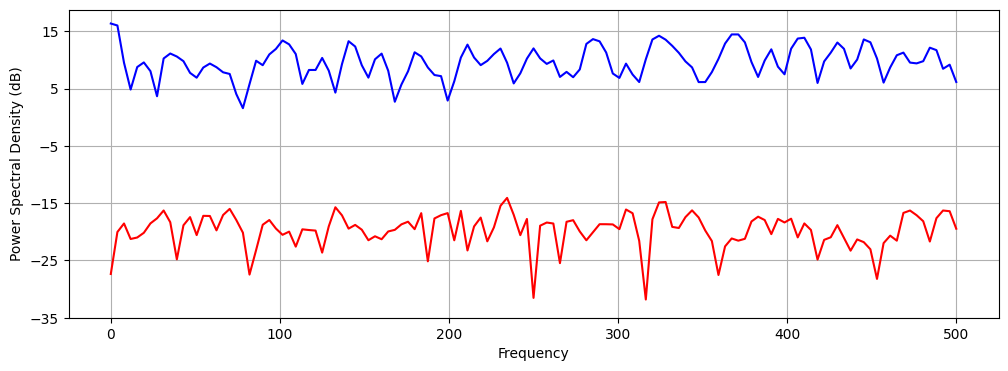

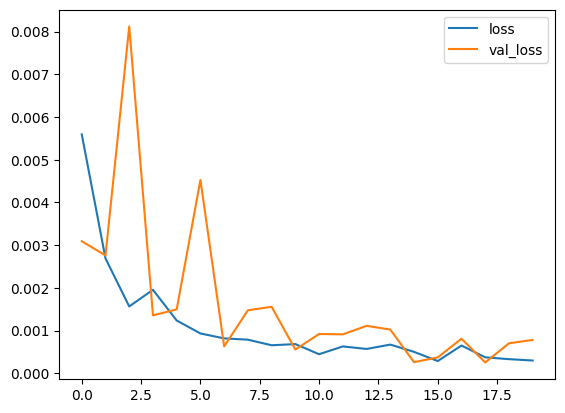

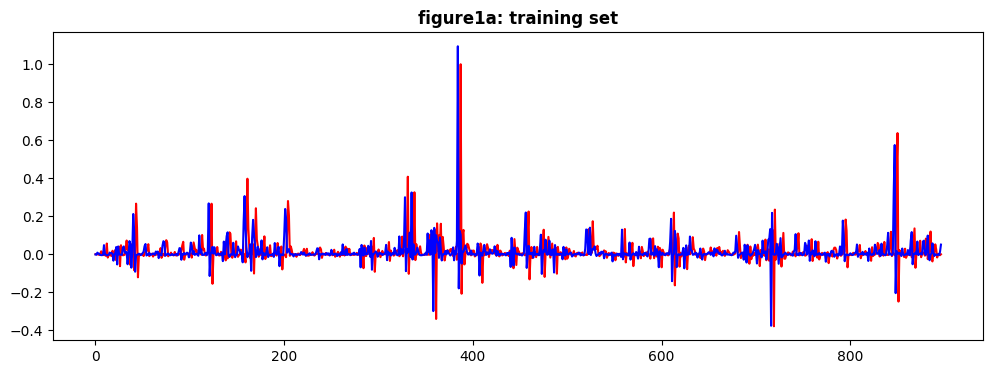

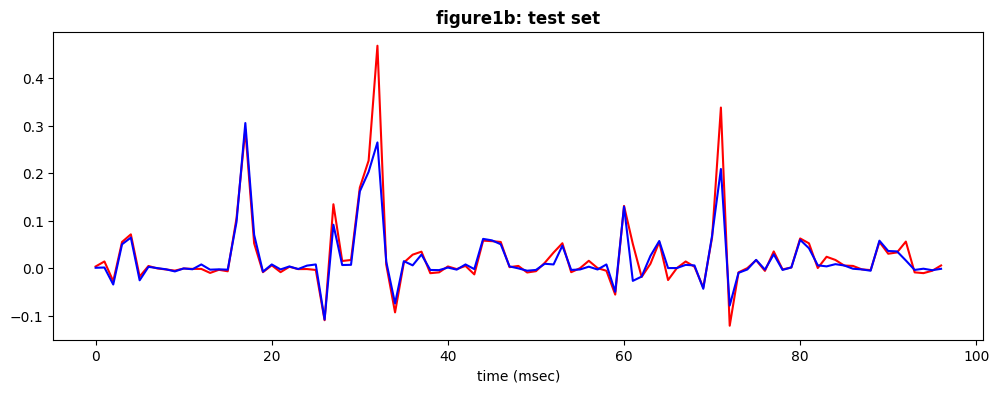

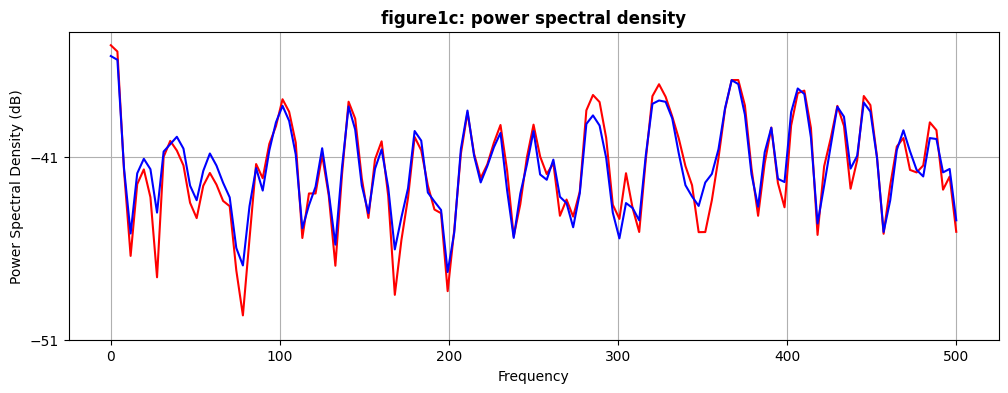

In [ ]:
## HOMEWORK volterra_order 4 implemented using additional hidden layer

#create a nonlinear signal from filtered white noise using a Volterra expansion

#here is the random number generator, same as before, to create the input
from numpy.random import default_rng
rng = default_rng()
time_points = 1000
random_signal = rng.standard_normal(time_points)  #standard gaussian mean =0 std = 1

#now create the volterra kernel
volterra_memory = 3  #number of past timepoints that contribute to the expansion
volterra_order = 4   #maximum polynomial order; more than 2 is usually unwieldy
                    #note that volterra_order=1 just gives a linear filter
#calculate the length of the kernel.  1(constant term) + memory(linear term) + memory^2 in this case
filter_length = 1
for n in range(1, volterra_order+1):
  filter_length = filter_length + volterra_memory**n
y = np.zeros(volterra_memory)  #set the first ones to zero so outputs line up
#now make some random coefficients (normally these might come from a polynomial fitting routine)
volterra_coefficients = rng.standard_normal(filter_length)

#now run the volterra kernel over the input to generate the output
for t in range(0,time_points-volterra_memory):
    x = random_signal[t:t+volterra_memory]  #last 3 time points
    xn = [1]  #constant term in volterra expansion
    inp = [1]
    for n in range(1,volterra_order+1):  #loop over the power (order) of volterra terms
      xn = np.outer(xn,x).ravel()    #this creates all the products x(t-i)x(t-j)...x(t-w) for the n'th order term
      inp = np.append(inp,xn)        #include all the terms, constant+linear+secondorder+...
                                     #each term has length volterra_memory**n including all possible cross-products
    y = np.append(y,np.dot(inp,volterra_coefficients))  #dot product multiplies by volterra coefficients to get output

#scale the range; tensorflow models learn more slowly if the output range is large
nonlinear_filtered_signal = y / np.max(np.abs(y))

plt.figure(figsize=(12,4))
plt.plot(random_signal,'r')
plt.title('input')
plt.figure(figsize=(12,4))
plt.plot(nonlinear_filtered_signal);
plt.title('nonlinear filtered');

plt.figure(figsize=(12,4))
plt.psd(random_signal, color='r', Fs=1000, scale_by_freq=0);
plt.psd(y, Fs=1000, color = 'b', scale_by_freq=0);


#Make a series and dataframe with integer "timestamps"
randSeries = pd.Series(name='random', data=random_signal, index=range(0,len(random_signal)))
randDataFrame = randSeries.to_frame(name="random")
fsSeries = pd.Series(name='filtered', data=nonlinear_filtered_signal, index=range(0,len(filtered_signal)))
fsDataFrame = fsSeries.to_frame(name="filtered")

#will use the last test_size elements in the series for test set validation and early stopping
#  in this case we need both the original random series and the filtered series
#  so we can predict one from the other
test_size = 100
test_ind = len(fsDataFrame)-test_size  #index of the first element to predict -1
fsTrain=fsDataFrame.iloc[:test_ind]  #train on everything before that
fsTest=fsDataFrame.iloc[test_ind:]   #test on everything after that
randTrain=randDataFrame.iloc[:test_ind]
randTest=randDataFrame.iloc[test_ind:]
#we will not do scaling this time, because we like the original scale (standard normal)
#generator for the timeseries data
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
predict_length = volterra_memory  #this is cheating; we know the length of the filter
#we are trying to "learn" the filter.  input is random sequence output is filtered sequence
#WARNING: you cannot pass a dataframe to timeseriesgenerator.  must be a numpy array
generator = TimeseriesGenerator(randTrain.to_numpy(), fsTrain.to_numpy(), length = predict_length, batch_size=1)

#generator for the validation data
validation_generator = TimeseriesGenerator(randTest.to_numpy(),fsTest.to_numpy(), length=predict_length, batch_size=1)
#create the network
n_features = 1

#will use two nonlinear layers so that we can capture second-order interactions between inputs in the first layer
model = Sequential()
model.add(Flatten(input_shape = (predict_length, n_features)))
model.add(Dense(80, activation='relu'))  #we know this will be a smooth (polynomial) function, so use smooth activation
model.add(Dense(20, activation = 'relu'))
model.add(Dense(1))  #this is a single output linear network at the top to allow scaling to the correct output range
model.compile(optimizer='adam', loss='mse')  #mse because is a regression problem
model.summary()
#longer early stopping because the first few iterations often dont seem to decrease the error
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(monitor='val_loss',patience=5)



#it can often take a while before the error starts to decrease.  if it gets stuck, try again
model.fit(generator,epochs=20,
                    validation_data=validation_generator,
                   callbacks=[early_stop])
losses = pd.DataFrame(model.history.history)
losses.plot();



#compare the predicted timeseries
predicted_outputs = model.predict(generator)
predicted_validation = model.predict(validation_generator)

plt.figure(figsize=(12,4), linewidth = 1)
plt.plot(nonlinear_filtered_signal[:len(predicted_outputs)],'r')
plt.plot(predicted_outputs,'b')
plt.title('figure1a: training set',fontweight="bold")
plt.figure(figsize=(12,4), linewidth = 1)
plt.plot(nonlinear_filtered_signal[-len(predicted_validation):],'r')
plt.plot(predicted_validation,'b')
plt.title('figure1b: test set',fontweight="bold");
plt.xlabel('time (msec)')

plt.figure(figsize=(12,4))
plt.psd(nonlinear_filtered_signal, color='r', Fs=1000, scale_by_freq=0);
plt.psd(predicted_outputs.ravel(), Fs=1000, color = 'b', scale_by_freq=0);  #use ravel to make a horizontal array
plt.title('figure1c: power spectral density',fontweight="bold");


In [ ]:
%%shell
jupyter nbconvert --to html /content/EECS253_2025_Lecture3.ipynb

[NbConvertApp] Converting notebook /content/EECS253_2025_Lecture3.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 34 image(s).
[NbConvertApp] Writing 3047039 bytes to /content/EECS253_2025_Lecture3.html
